# NB02 — Simulasi CVD Machado pada manifest penuh

Notebook menggunakan seluruh baris manifest NB01 tanpa balancing atau undersampling.

- **Adaptasi penelitian:** tipe protan/deutan dan severity 0,25; 0,50; 0,75; 1,00.
- **Keputusan implementasi:** PNG lossless, checkpoint resume, progress log, struktur folder,
  mean absolute RGB change dan gamut clipping sebagai diagnostik teknis non-validasi.

Severity di bawah 1 dilaporkan sebagai keluarga protan/deutan (anomalous endpoint model),
sedangkan severity 1 adalah endpoint protanopia/deuteranopia. Output bukan diagnosis klinis.

In [1]:
%pip install opencv-python-headless numpy pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "machado.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("core/machado.py tidak ditemukan")
sys.path.insert(0, str(CORE_DIR))
from machado import IMPLEMENTATION_VERSION as MACHADO_CORE_VERSION, simulate_machado_bgr
from utils import ensure_directories, find_research_root, sha256_file, utc_timestamp, write_csv, write_json

RESEARCH_ROOT = find_research_root("notebooks/01/output/dataset_preparation_report.csv")
NB01_REPORT_PATH = RESEARCH_ROOT / "notebooks" / "01" / "output" / "dataset_preparation_report.csv"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "02" / "output"
SIMULATED_DIR = OUTPUT_DIR / "simulated_images"
FIGURES_DIR = OUTPUT_DIR / "figures"
ensure_directories([OUTPUT_DIR, SIMULATED_DIR, FIGURES_DIR])

METHOD_VERSION = "machado-2009-matrix-1.1"
CVD_FAMILIES = ("protan", "deutan")
SEVERITIES = (0.25, 0.50, 0.75, 1.00)
REPORT_INTERVAL = 1000
COMPOSITE_KEY = ["subset", "source_class", "source_file_name", "cvd_family", "severity"]
PROGRESS_KEY = ["method_version", "processed_records"]
REPORT_PATH = OUTPUT_DIR / "simulation_report.csv"
CHECKPOINT_PATH = OUTPUT_DIR / "simulation_checkpoint.csv"
PROGRESS_PATH = OUTPUT_DIR / "simulation_progress.csv"
ERROR_PATH = OUTPUT_DIR / "simulation_errors.csv"
SUMMARY_PATH = OUTPUT_DIR / "simulation_summary.json"
MACHADO_CORE_PATH = CORE_DIR / "machado.py"
MACHADO_CORE_SHA256 = sha256_file(MACHADO_CORE_PATH)

manifest = pd.read_csv(NB01_REPORT_PATH)
manifest_sha256 = sha256_file(NB01_REPORT_PATH)
if manifest.duplicated(["subset", "source_class", "source_file_name"]).any():
    raise ValueError("Manifest NB01 memiliki composite key duplikat")
missing_files = manifest.loc[~manifest["output_path"].map(lambda value: Path(value).exists()), "output_path"]
if len(missing_files):
    raise FileNotFoundError(
        f"{len(missing_files):,} file manifest NB01 tidak tersedia. Jalankan ulang NB01; "
        "NB02 tidak akan mengganti file hilang dengan undersampling."
    )
checksum_mismatch = manifest.loc[
    manifest.apply(lambda row: sha256_file(Path(row["output_path"])) != row["output_sha256"], axis=1)
]
if len(checksum_mismatch):
    raise ValueError(f"{len(checksum_mismatch):,} checksum file tidak sesuai manifest NB01")
print(manifest.groupby("hue_range").size())
print(f"Sumber penuh: {len(manifest):,}; expected simulations: {len(manifest) * len(CVD_FAMILIES) * len(SEVERITIES):,}")

hue_range
green_yellow    1150
red_orange      2040
dtype: int64
Sumber penuh: 3,190; expected simulations: 25,520


In [3]:
def severity_folder(severity: float) -> str:
    return f"severity_{int(round(severity * 100)):03d}"


def condition_label(cvd_family: str, severity: float) -> str:
    if severity < 1.0:
        return "protanomaly_model" if cvd_family == "protan" else "deuteranomaly_model"
    return "protanopia_endpoint" if cvd_family == "protan" else "deuteranopia_endpoint"


def build_jobs() -> list[dict]:
    jobs = []
    for row in manifest.to_dict(orient="records"):
        for cvd_family in CVD_FAMILIES:
            for severity in SEVERITIES:
                output_path = SIMULATED_DIR / cvd_family / severity_folder(severity) / row["hue_range"] / row["output_file_name"]
                jobs.append({
                    "subset": row["subset"], "source_class": row["source_class"], "source_file_name": row["source_file_name"],
                    "hue_range": row["hue_range"], "source_path": row["output_path"],
                    "source_sha256": row["output_sha256"], "output_file_name": row["output_file_name"],
                    "cvd_family": cvd_family, "severity": float(severity), "condition_label": condition_label(cvd_family, severity),
                    "simulated_path": str(output_path), "machado_module_sha256": MACHADO_CORE_SHA256,
                })
    return jobs


def job_key(record: dict) -> tuple:
    return tuple(record[column] for column in COMPOSITE_KEY)


def progress_record(processed_records: int, successful_records: int, error_records: int, elapsed: float) -> dict:
    total_records = len(jobs)
    if processed_records == total_records:
        status = "completed" if error_records == 0 else "completed_with_errors"
    else:
        status = "running"
    return {
        "method_version": METHOD_VERSION, "processed_records": processed_records,
        "total_records": total_records, "successful_records": successful_records,
        "error_records": error_records, "remaining_records": total_records - processed_records,
        "completion_fraction": processed_records / total_records, "status": status,
        "run_elapsed_seconds": float(elapsed), "updated_at": utc_timestamp(),
    }


jobs = build_jobs()
existing = pd.read_csv(CHECKPOINT_PATH) if CHECKPOINT_PATH.exists() else pd.DataFrame()
if not existing.empty and set(existing["method_version"]) != {METHOD_VERSION}:
    raise ValueError("Method version pada checkpoint berbeda; pindahkan output lama sebelum rerun")
jobs_by_key = {job_key(job): job for job in jobs}
report_rows = []
for row in existing.to_dict(orient="records"):
    key = job_key(row)
    job = jobs_by_key.get(key)
    if job is None:
        continue
    lineage_fields = ("hue_range", "source_path", "source_sha256", "simulated_path", "machado_module_sha256")
    lineage_matches = all(row.get(field) == job[field] for field in lineage_fields)
    simulated_path = Path(row["simulated_path"])
    checksum_matches = simulated_path.exists() and row.get("simulated_sha256") == sha256_file(simulated_path)
    if lineage_matches and checksum_matches:
        report_rows.append(row)
completed = {job_key(row) for row in report_rows}
error_rows = []

In [4]:
run_start, processed, progress_rows = time.perf_counter(), 0, []
for job in jobs:
    if job_key(job) in completed:
        continue
    started = time.perf_counter()
    error_stage = "image_read"
    try:
        original = cv2.imread(job["source_path"])
        if original is None:
            raise ValueError("cv2.imread returned None")
        error_stage = "machado_simulation"
        simulated, diagnostics = simulate_machado_bgr(original, job["cvd_family"], job["severity"])
        output_path = Path(job["simulated_path"])
        output_path.parent.mkdir(parents=True, exist_ok=True)
        error_stage = "image_write"
        if not cv2.imwrite(str(output_path), simulated):
            raise IOError("cv2.imwrite failed")
        mean_change = float(np.abs(simulated.astype(np.float32) - original.astype(np.float32)).mean() / 255.0)
        report_rows.append({
            **{column: job[column] for column in COMPOSITE_KEY}, "hue_range": job["hue_range"],
            "condition_label": job["condition_label"], "source_path": job["source_path"],
            "source_sha256": job["source_sha256"], "simulated_path": job["simulated_path"],
            "simulated_sha256": sha256_file(output_path),
            "machado_module_sha256": job["machado_module_sha256"], "mean_absolute_rgb_change": mean_change,
            **diagnostics, "processing_seconds": float(time.perf_counter() - started), "method_version": METHOD_VERSION,
        })
    except Exception as exc:
        error_rows.append({
            **{column: job[column] for column in COMPOSITE_KEY}, "source_path": job["source_path"],
            "simulated_path": job["simulated_path"], "error_stage": error_stage,
            "error_type": type(exc).__name__, "error_message": str(exc),
        })
    processed += 1
    attempted_records = len(completed) + processed
    if processed % REPORT_INTERVAL == 0 or attempted_records == len(jobs):
        checkpoint = pd.DataFrame(report_rows).drop_duplicates(COMPOSITE_KEY, keep="last").sort_values(COMPOSITE_KEY)
        progress_rows.append(progress_record(
            attempted_records, len(checkpoint), len(error_rows), time.perf_counter() - run_start,
        ))
        write_csv(checkpoint, CHECKPOINT_PATH, COMPOSITE_KEY, allow_empty=True)
        write_csv(pd.DataFrame(progress_rows), PROGRESS_PATH, PROGRESS_KEY)
        print(f"{attempted_records:,}/{len(jobs):,} simulasi diperiksa")

report = pd.DataFrame(report_rows).drop_duplicates(COMPOSITE_KEY, keep="last").sort_values(COMPOSITE_KEY).reset_index(drop=True)
errors = pd.DataFrame(error_rows, columns=[*COMPOSITE_KEY, "source_path", "simulated_path", "error_stage", "error_type", "error_message"])
attempted_records = len(completed) + processed
if not progress_rows:
    progress_rows.append(progress_record(
        attempted_records, len(report), len(errors), time.perf_counter() - run_start,
    ))
progress = pd.DataFrame(progress_rows).sort_values(PROGRESS_KEY).reset_index(drop=True)
write_csv(report, REPORT_PATH, COMPOSITE_KEY)
write_csv(report, CHECKPOINT_PATH, COMPOSITE_KEY)
write_csv(progress, PROGRESS_PATH, PROGRESS_KEY)
write_csv(errors, ERROR_PATH, COMPOSITE_KEY, allow_empty=True)
expected_records = len(jobs)
if len(report) != expected_records:
    raise RuntimeError(f"Simulasi belum lengkap: {len(report):,}/{expected_records:,}; periksa error CSV")

1,000/25,520 simulasi diperiksa
2,000/25,520 simulasi diperiksa
3,000/25,520 simulasi diperiksa
4,000/25,520 simulasi diperiksa
5,000/25,520 simulasi diperiksa
6,000/25,520 simulasi diperiksa
7,000/25,520 simulasi diperiksa
8,000/25,520 simulasi diperiksa
9,000/25,520 simulasi diperiksa
10,000/25,520 simulasi diperiksa
11,000/25,520 simulasi diperiksa
12,000/25,520 simulasi diperiksa
13,000/25,520 simulasi diperiksa
14,000/25,520 simulasi diperiksa
15,000/25,520 simulasi diperiksa
16,000/25,520 simulasi diperiksa
17,000/25,520 simulasi diperiksa
18,000/25,520 simulasi diperiksa
19,000/25,520 simulasi diperiksa
20,000/25,520 simulasi diperiksa
21,000/25,520 simulasi diperiksa
22,000/25,520 simulasi diperiksa
23,000/25,520 simulasi diperiksa
24,000/25,520 simulasi diperiksa
25,000/25,520 simulasi diperiksa
25,520/25,520 simulasi diperiksa


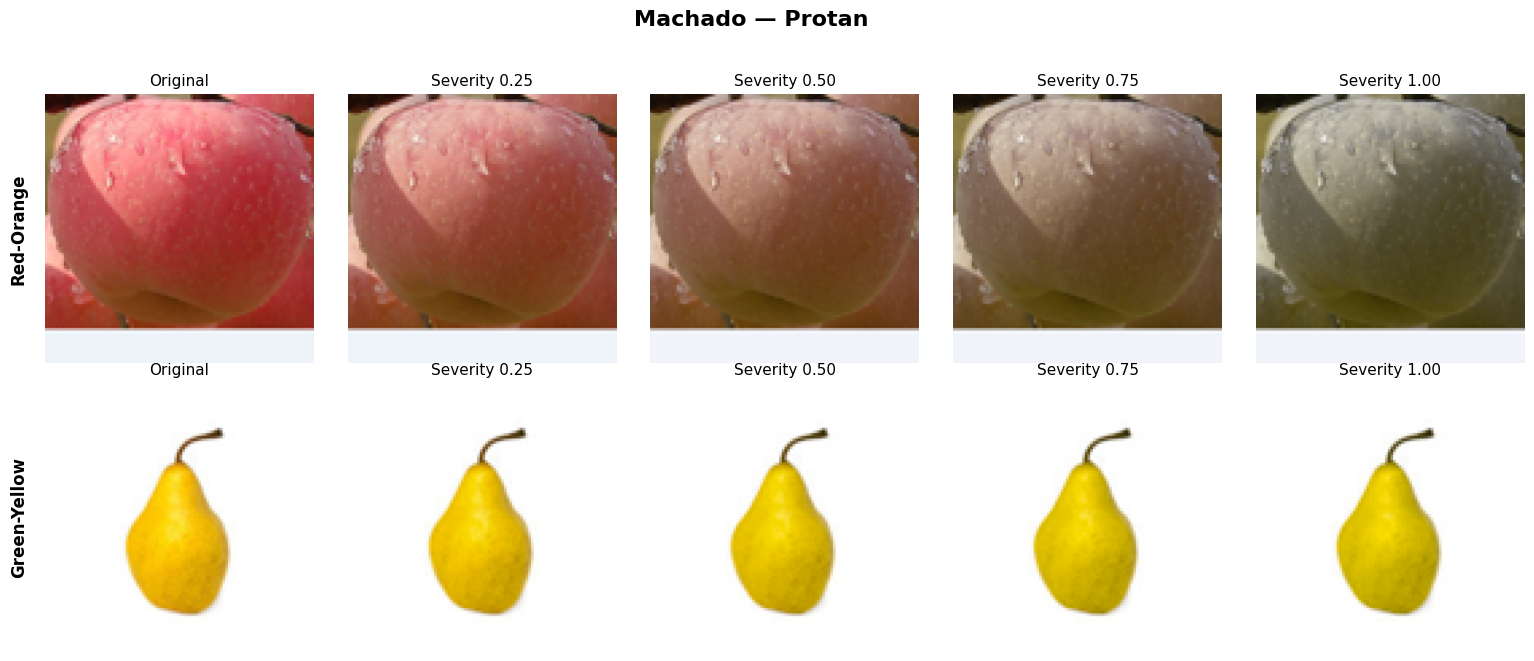

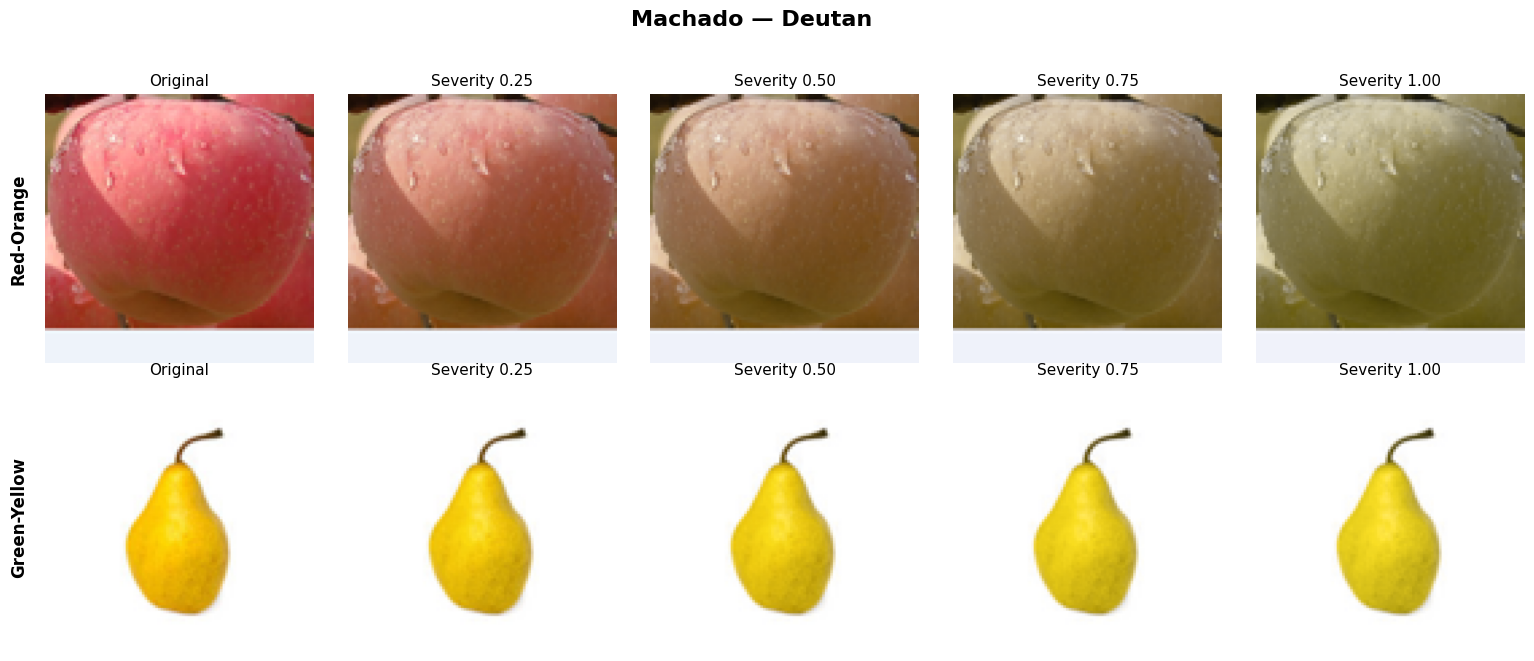

{
  "notebook": "NB02_simulation",
  "method_version": "machado-2009-matrix-1.1",
  "formula_source": {
    "simulation": "Machado, Oliveira, and Fernandes (2009), DOI 10.1109/TVCG.2009.113",
    "matrices": "published severity matrices from the authors' supplementary dataset",
    "interpolation": "piecewise linear interpolation between adjacent Machado matrices, as implemented by Colour Science matrix_cvd_Machado2009",
    "transfer": "sRGB IEC 61966-2-1"
  },
  "research_adaptation": {
    "cvd_scope": "protan and deutan families",
    "severity_levels": [
      0.25,
      0.5,
      0.75,
      1.0
    ],
    "dataset_scope": "all NB01 manifest records without balancing or undersampling"
  },
  "implementation_decision": {
    "image_format": "PNG lossless",
    "resume_storage": "simulation_checkpoint.csv",
    "progress_storage": "simulation_progress.csv checkpoint log",
    "diagnostic_role": "mean RGB change and gamut clipping are engineering sanity-checks, not validation metr

In [5]:
HUE_ORDER = ("red_orange", "green_yellow")

representative = {
    hue_range: Path(
        manifest.loc[manifest["hue_range"].eq(hue_range)]
        .sort_values(["source_class", "source_file_name"])
        .iloc[0]["output_path"]
    )
    for hue_range in HUE_ORDER
}

figure_paths = []

for cvd_family in CVD_FAMILIES:
    fig, axes = plt.subplots(
        nrows=len(HUE_ORDER),
        ncols=len(SEVERITIES) + 1,
        figsize=(16, 6.6),
        squeeze=False,
    )

    for row_index, hue_range in enumerate(HUE_ORDER):
        source_path = representative[hue_range]
        original = cv2.imread(str(source_path))

        if original is None:
            raise ValueError(f"Gagal membaca citra: {source_path}")

        images = [("Original", original)]

        for severity in SEVERITIES:
            simulated, _ = simulate_machado_bgr(original, cvd_family, severity)
            images.append((f"Severity {severity:.2f}", simulated))

        for column_index, (title, image) in enumerate(images):
            axis = axes[row_index, column_index]
            axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            axis.set_facecolor("white")
            axis.set_title(title, fontsize=11)
            axis.set_xticks([])
            axis.set_yticks([])
            for spine in axis.spines.values():
                spine.set_visible(False)

        axes[row_index, 0].set_ylabel(
            hue_range.replace("_", "-").title(), fontsize=12, fontweight="bold", labelpad=12,
        )

    family_title = {
        "protan": "Machado — Protan",
        "deutan": "Machado — Deutan",
    }.get(cvd_family, f"Machado — {cvd_family.title()}")

    fig.suptitle(family_title, fontsize=16, fontweight="bold", y=0.995)
    fig.tight_layout(rect=(0.02, 0.0, 1.0, 0.96), h_pad=1.2, w_pad=0.8)

    figure_path = FIGURES_DIR / f"simulation_severity_{cvd_family}.png"
    fig.savefig(figure_path, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    figure_paths.append(str(figure_path))
    
group_summary = report.groupby(["cvd_family", "severity", "hue_range"], as_index=False).agg(
    records=("source_file_name", "size"), median_rgb_change=("mean_absolute_rgb_change", "median"),
    median_clip_ratio=("clip_any_ratio", "median"), median_processing_seconds=("processing_seconds", "median"),
)
summary = {
    "notebook": "NB02_simulation", "method_version": METHOD_VERSION,
    "formula_source": {
        "simulation": "Machado, Oliveira, and Fernandes (2009), DOI 10.1109/TVCG.2009.113",
        "matrices": "published severity matrices from the authors' supplementary dataset",
        "interpolation": "piecewise linear interpolation between adjacent Machado matrices, as implemented by Colour Science matrix_cvd_Machado2009",
        "transfer": "sRGB IEC 61966-2-1",
    },
    "research_adaptation": {
        "cvd_scope": "protan and deutan families",
        "severity_levels": list(SEVERITIES),
        "dataset_scope": "all NB01 manifest records without balancing or undersampling",
    },
    "implementation_decision": {
        "image_format": "PNG lossless",
        "resume_storage": "simulation_checkpoint.csv",
        "progress_storage": "simulation_progress.csv checkpoint log",
        "diagnostic_role": "mean RGB change and gamut clipping are engineering sanity-checks, not validation metrics",
    },
    "parameters": {
        "cvd_families": list(CVD_FAMILIES), "severities": list(SEVERITIES),
        "image_format": "PNG", "report_interval": REPORT_INTERVAL,
        "machado_core_version": MACHADO_CORE_VERSION,
    },
    "sample_counts": {"source_images": int(len(manifest)), "source_distribution": {key: int(value) for key, value in manifest.groupby("hue_range").size().items()}},
    "record_counts": {
        "expected": expected_records, "success": int(len(report)), "errors": int(len(errors)),
        "checkpoint_records": int(len(report)), "progress_checkpoints": int(len(progress)),
    },
    "statistics": {
        "records_by_group": group_summary[["cvd_family", "severity", "hue_range", "records"]].to_dict(orient="records"),
    },
    "implementation_diagnostics": {
        "role": "engineering sanity-check only; not an evaluation or validation metric",
        "mean_absolute_rgb_change_definition": "mean absolute uint8 RGB difference divided by 255",
        "gamut_clipping_definition": "fraction of pixels with any transformed linear-RGB channel outside [0, 1] before clipping",
        "median_rgb_change": float(report["mean_absolute_rgb_change"].median()),
        "median_clip_ratio": float(report["clip_any_ratio"].median()),
        "group_summary": group_summary.to_dict(orient="records"),
    },
    "output_contract": {
        "undersampling": False, "manifest_is_source_of_truth": True,
        "input_manifest_sha256": manifest_sha256, "machado_module_sha256": MACHADO_CORE_SHA256,
        "composite_key": COMPOSITE_KEY, "checkpoint_composite_key": COMPOSITE_KEY,
        "progress_composite_key": PROGRESS_KEY, "diagnostics_are_not_validation": True,
    },
    "outputs": {
        "report_csv": str(REPORT_PATH), "checkpoint_csv": str(CHECKPOINT_PATH),
        "progress_csv": str(PROGRESS_PATH), "error_csv": str(ERROR_PATH),
        "simulated_images": str(SIMULATED_DIR), "figures": figure_paths,
    },
    "created_at": utc_timestamp(),
}
write_json(summary, SUMMARY_PATH)
print(json.dumps(summary, indent=2, ensure_ascii=False))